# 06 – Gradient boosting (HistGradientBoosting)

Also a tree ensemble, but built differently from the Random Forest:
trees are added **one after another**, and each new tree learns to correct the errors of all the previous ones.
This is usually the strongest model type for tabular data.

We use scikit-learn's `HistGradientBoostingClassifier`. It works like LightGBM: it bins every feature into
≤ 255 buckets, which makes training fast. LightGBM itself would need an extra system library on this Mac.

Preprocessing: **none**. NaN is handled natively (the model learns which side of each split missing values go to).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from utils import load_features, compare_to_baseline, save_predictions

# same plot style as in the other notebooks
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": GREY, "xtick.color": GREY, "ytick.color": GREY,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "figure.dpi": 110,
})

# data + features from features.py (target encodings learned on dev only)
dev, valid, test, X_dev, X_valid, X_test = load_features()
y_dev, y_valid = dev["music_hit"], valid["music_hit"]
print("X_dev:", X_dev.shape, "| X_valid:", X_valid.shape, "| X_test:", X_test.shape)

X_dev: (280040, 191) | X_valid: (70011, 191) | X_test: (87513, 191)


## Train with early stopping
More trees isn't always better: at some point the model starts memorising the training data.
**Early stopping** keeps 10 % of dev aside internally and stops adding trees when the score on that part
hasn't improved for 50 rounds. The validation set stays untouched.

In [2]:
import time
from sklearn.ensemble import HistGradientBoostingClassifier

model = HistGradientBoostingClassifier(
    max_iter=2000,            # upper limit on the number of trees
    learning_rate=0.05,       # how strongly each new tree corrects the previous ones
    max_leaf_nodes=63,        # size of each tree
    min_samples_leaf=50,      # each leaf needs >= 50 songs
    l2_regularization=1.0,    # penalty on extreme leaf values
    early_stopping=True,      # stop when the internal 10 % no longer improves
    validation_fraction=0.1,
    n_iter_no_change=50,
    scoring="roc_auc",        # 'improve' = higher AUC on the internal 10 %
    random_state=42,
)

start = time.time()
model.fit(X_dev, y_dev)
print(f"training took {time.time() - start:.0f} s, stopped after {model.n_iter_} trees")

training took 43 s, stopped after 390 trees


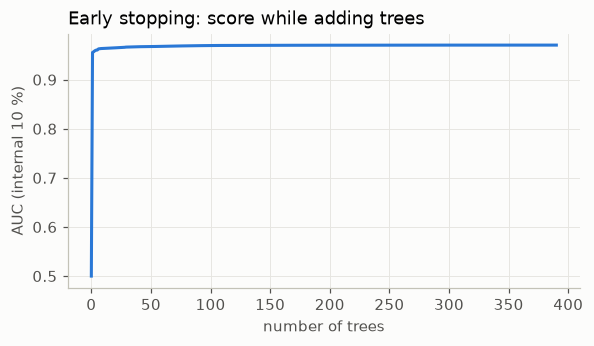

In [3]:
# learning curve: AUC on the internal early-stopping set after each tree
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(model.validation_score_, color=BLUE, lw=2)
ax.set_xlabel("number of trees"); ax.set_ylabel("AUC (internal 10 %)")
ax.set_title("Early stopping: score while adding trees", loc="left")
plt.show()

## Validation AUC vs. baseline

In [4]:
valid_pred = model.predict_proba(X_valid)[:, 1]
auc = compare_to_baseline("Gradient boosting", y_valid, valid_pred)

Gradient boosting: validation AUC = 0.9699
baseline (artist_followers alone)  = 0.8747
improvement                        = +0.0952


## Which features matter? (permutation importance)
Boosting has no built-in importance in scikit-learn, so we use a simple trick: **shuffle one feature**
on (a sample of) the validation set and measure how much the AUC drops. A large drop means the model relies on that feature.

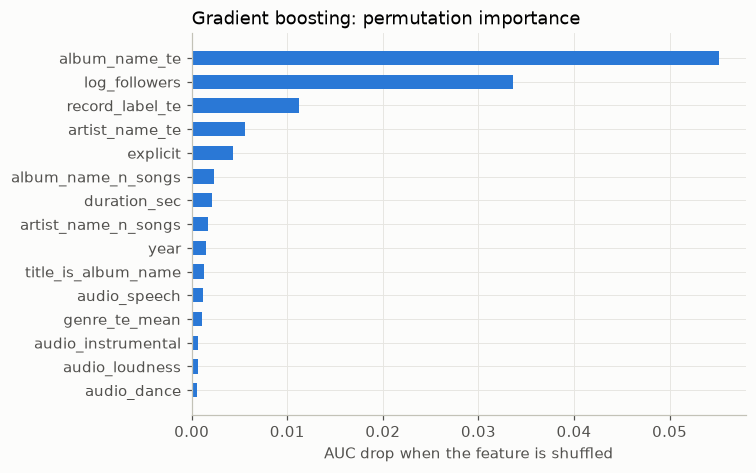

In [5]:
def plot_top_features(values, title, xlabel, n=15):
    """Horizontal bar chart of the n largest values (e.g. feature importances)."""
    top = values.sort_values(ascending=False).head(n)[::-1]  # biggest at the top
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.barh(top.index, top.values, color=BLUE, height=0.6)
    ax.set_xlabel(xlabel)
    ax.set_title(title, loc="left")
    plt.show()

from sklearn.inspection import permutation_importance

sample = X_valid.sample(20000, random_state=42)  # a sample keeps this fast
result = permutation_importance(model, sample, y_valid.loc[sample.index], scoring="roc_auc",
                                n_repeats=3, random_state=42, n_jobs=-1)
importance = pd.Series(result.importances_mean, index=X_valid.columns)
plot_top_features(importance, "Gradient boosting: permutation importance", "AUC drop when the feature is shuffled")

In [6]:
test_pred = model.predict_proba(X_test)[:, 1]
save_predictions("gradient_boosting", valid, valid_pred, test, test_pred)